<a href="https://colab.research.google.com/github/jaquespires77-afk/Econometrics-foundations/blob/main/01_heterocedasticidade_hc3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 15 — Heterocedasticidade e erros-padrão robustos HC3

Objetivo: compreender como a heterocedasticidade afeta a inferência estatística e por que os erros-padrão robustos HC3 podem mudar a incerteza sem alterar o coeficiente estimado.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(42)

n = 500

educacao = rng.uniform(8, 20, n)

desvio_erro = 100 + 50 * (educacao - 8)

erro = rng.normal(0, 1, n) * desvio_erro

salario = 1000 + 300 * educacao + erro

dados = pd.DataFrame({
    "salario": salario,
    "educacao": educacao
})

dados.head()

,salario,educacao
0,6995.110247,17.287473
1,5013.214141,13.266541
2,6848.222625,18.303175
3,5881.087315,16.368416
4,3712.368574,9.130128


In [3]:
modelo_convencional = smf.ols(
    "salario ~ educacao",
    data=dados
).fit()

print(modelo_convencional.summary())

                            OLS Regression Results                            
Dep. Variable:                salario   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                     2556.
Date:                Sat, 07 Nov 2026   Prob (F-statistic):          2.94e-198
Time:                        17:36:54   Log-Likelihood:                -3758.8
No. Observations:                 500   AIC:                             7522.
Df Residuals:                     498   BIC:                             7530.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1063.2458     83.370     12.753      0.0

In [4]:
modelo_robusto = smf.ols(
    "salario ~ educacao",
    data=dados
).fit(cov_type="HC3")

print(modelo_robusto.summary())

                            OLS Regression Results                            
Dep. Variable:                salario   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.837
Method:                 Least Squares   F-statistic:                     2281.
Date:                Sat, 07 Nov 2026   Prob (F-statistic):          4.89e-188
Time:                        17:36:54   Log-Likelihood:                -3758.8
No. Observations:                 500   AIC:                             7522.
Df Residuals:                     498   BIC:                             7530.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1063.2458     72.851     14.595      0.0

In [5]:
comparacao = pd.DataFrame({
    "Coeficiente": [
        modelo_convencional.params["educacao"],
        modelo_robusto.params["educacao"]
    ],
    "Erro-padrao": [
        modelo_convencional.bse["educacao"],
        modelo_robusto.bse["educacao"]
    ],
    "Estatistica_t": [
        modelo_convencional.tvalues["educacao"],
        modelo_robusto.tvalues["educacao"]
    ],
    "Valor_p": [
        modelo_convencional.pvalues["educacao"],
        modelo_robusto.pvalues["educacao"]
    ]
}, index=["Convencional", "HC3"])

comparacao.round(4)

,Coeficiente,Erro-padrao,Estatistica_t,Valor_p
Convencional,293.4065,5.8035,50.5572,0.0
HC3,293.4065,6.1438,47.7566,0.0


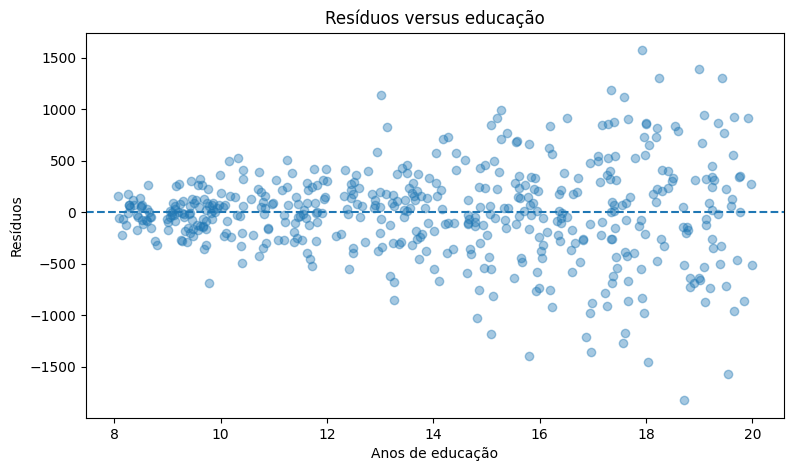

In [6]:
residuos = modelo_convencional.resid

plt.figure(figsize=(9, 5))

plt.scatter(
    dados["educacao"],
    residuos,
    alpha=0.4
)

plt.axhline(0, linestyle="--")

plt.xlabel("Anos de educação")
plt.ylabel("Resíduos")
plt.title("Resíduos versus educação")

plt.show()

## Interpretação

O coeficiente permanece igual porque tanto o modelo convencional quanto o modelo HC3 utilizam os mesmos estimadores de Mínimos Quadrados Ordinários.

O que muda é a forma de estimar a incerteza do coeficiente.

O erro-padrão convencional pressupõe variância constante dos erros, enquanto o HC3 ajusta a matriz de variância-covariância para permitir heterocedasticidade.

Por isso, o coeficiente pode permanecer igual enquanto o erro-padrão, a estatística t, o valor-p e o intervalo de confiança mudam.

Interpretação econômica.                                                          
Neste exercício, a heterocedasticidade foi construída de propósito: níveis maiores de educação apresentam maior dispersão salarial ao redor da reta estimada.

O MQO continua estimando a mesma associação média entre educação e salário, mas a inferência convencional pode representar incorretamente a incerteza dessa associação.

Esse é o primeiro passo para compreender a inferência robusta aplicada a dados econômicos reais.